In [34]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn import preprocessing

from sklearn.pipeline import make_pipeline

from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

df = pd.read_csv("../data/forest+fires/forestfires.csv", delimiter=",")

In [35]:
# Split the data
from sklearn.model_selection import train_test_split

categorical_columns = ["month", "day"]
numerical_columns = ['X', 'Y', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']

X = df[categorical_columns + numerical_columns]
y = df["area"]
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

In [36]:
#Setting up Preprocessing Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, RobustScaler, OneHotEncoder


categorical_pipe = make_pipeline(
    OneHotEncoder(handle_unknown="ignore")
)
numerical_pipe = make_pipeline(
    SimpleImputer(strategy="median"),
    RobustScaler()
)

preprocessing = ColumnTransformer(
    [
        ("cat", categorical_pipe, categorical_columns),
        ("num", numerical_pipe, numerical_columns),
    ],
    verbose_feature_names_out=False,
)

Model:  Mean 
Mean Absolute Error:  21.33978393957464 
Root Mean Squared Error:  97.46955760716725 
R2 Score:  -0.002757468434611221 


Model:  Median 
Mean Absolute Error:  16.646846153846152 
Root Mean Squared Error:  98.68148218072433 
R2 Score:  -0.027848823816304602 


Model:  0 
Mean Absolute Error:  16.67330769230769 
Root Mean Squared Error:  98.75317245536975 
R2 Score:  -0.029342792672087503 


Model:  Linear Regression 
Mean Absolute Error:  21.68061482736573 
Root Mean Squared Error:  96.53407383271485 
R2 Score:  0.01639849652747205 


Model:  Ridge 
Mean Absolute Error:  21.330935712710687 
Root Mean Squared Error:  97.0484986570831 
R2 Score:  0.005887446811468577 


Model:  KNN n = 3  
Mean Absolute Error:  20.532333333333334 
Root Mean Squared Error:  94.19951702518316 
R2 Score:  0.06339759709164405 


Model:  KNN n = 7  
Mean Absolute Error:  20.769424908424906 
Root Mean Squared Error:  97.38400403329926 
R2 Score:  -0.0009979070589851702 


Model:  Random Forest 
M

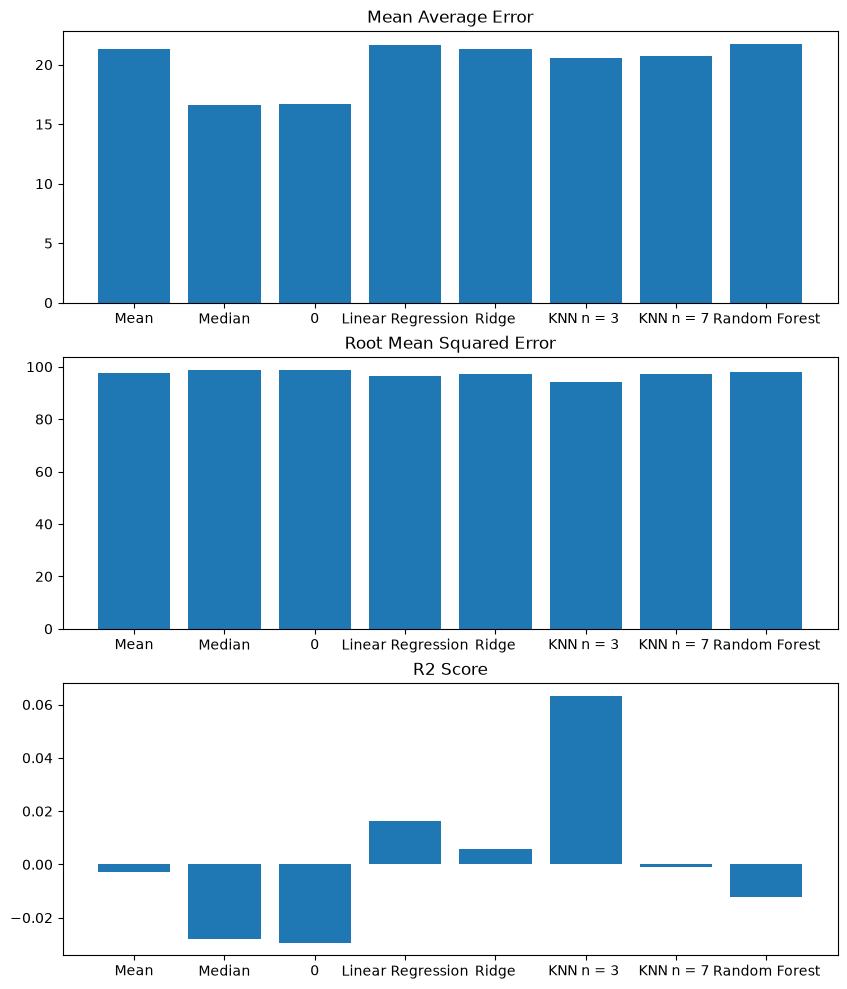

In [49]:
# Trying Different Models
from sklearn.linear_model import LinearRegression, RidgeCV, GammaRegressor
from sklearn.dummy import DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    "Mean" : DummyRegressor(strategy="mean"),
    "Median" : DummyRegressor(strategy="median"),
    "0" : DummyRegressor(strategy="constant", constant = 0.0),
    "Linear Regression": LinearRegression(),
    "Ridge" : RidgeCV(alphas=[0.01,0.1,1,10,100]),
    "KNN n = 3 " : KNeighborsRegressor(n_neighbors=3), # Tried changing weights to "Distance", small negative impact on results
    "KNN n = 7 " : KNeighborsRegressor(n_neighbors=7),
    "KNN n = 7 " : KNeighborsRegressor(n_neighbors=21),
    "Random Forest": RandomForestRegressor(max_depth=2, random_state=123)
#    "Gamma Regressor": GammaRegressor() Doesn't work due to the 0s, normalisation fixes?
}

resultsMAE = {}
resultsRMSE = {}
resultsR2 = {}
# Run all of the models and print out their results
for name, model in models.items():
    model = make_pipeline(preprocessing, model)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    rmse = root_mean_squared_error(y_test, pred)
    r2 = r2_score(y_test, pred)

    resultsMAE.update({name:mae})
    resultsRMSE.update({name:rmse})
    resultsR2.update({name:r2})

    print("Model: ", name ,"\nMean Absolute Error: ", mae, "\nRoot Mean Squared Error: ", rmse,"\nR2 Score: ", r2 ,"\n\n")

plt.figure(figsize={10,12})
plt.subplot(311, title="Mean Average Error").bar(range(len(resultsMAE)),list(resultsMAE.values()))
plt.xticks(range(len(models.keys())),models.keys())

plt.subplot(312, title="Root Mean Squared Error").bar(range(len(resultsRMSE)),list(resultsRMSE.values()))
plt.xticks(range(len(models.keys())),models.keys())

plt.subplot(313, title="R2 Score").bar(range(len(resultsR2)),list(resultsR2.values()))
plt.xticks(range(len(models.keys())),models.keys())

plt.show()